In [15]:
import numpy as np
import matplotlib.pyplot as plt

## Constants & Initial Conditions:

In [16]:
M = 1.0
a = 0.95
u_phi_init = 0.022
r_initial = 10.0

# 1. Calculate Exact Metric Components at r=10
g_tt_init = -(1.0 - 2.0*M/r_initial)
g_tphi_init = -2.0*a*M/r_initial
g_phiphi_init = r_initial**2 + a**2 + (2.0*M*a**2)/r_initial

# 2. Solve for exact u^t using normalization condition
A = g_tt_init
B = 2.0 * g_tphi_init * u_phi_init
C = g_phiphi_init * (u_phi_init**2) + 1.0
ut_init = (-B - np.sqrt(B**2 - 4*A*C)) / (2*A)

# 3. Calculate Exact E and L (to 16 decimal places)
E = -(g_tt_init * ut_init + g_tphi_init * u_phi_init)
L = g_tphi_init * ut_init + g_phiphi_init * u_phi_init

print(f"Calculated Exact E: {E}")
print(f"Calculated Exact L: {L}")

Calculated Exact E: 0.9160550256398358
Calculated Exact L: 2.007255681410539


### Loading and exporting numerical solution data

In [17]:
numerical_data = np.load('numerical_trajectory.npz')
tau_numerical = numerical_data['tau']
r_numerical = numerical_data['r']

### Simulation Setup

In [18]:
tau_initial = 2.0
r_initial = np.interp(tau_initial, tau_numerical, r_numerical)
dtau = 0.01

## Metric & Potential Functions

In [19]:
def delta(r):
    return r**2 - 2*M*r + a**2

def R_eff(r):
    # Derived effective potential equation
    term1 = (E**2) * (r**3 + (a**2)*r + 2*M*(a**2))
    term2 = 4 * a * M * E * L
    term3 = (L**2) * (r - 2*M)
    term4 = r * delta(r)
    return term1 - term2 - term3 - term4

def dr_dtau(r):
    # dr/dtau = - sqrt( R / r^3 )
    # The max(0, ...) prevents math errors if R dips slightly below zero due to float limits
    R_val = max(0.0, R_eff(r)) 
    return -np.sqrt(R_val / (r**3))

## Analytical Equations for Velocity Cross-Check

In [20]:
def get_covariant_velocities(r):
    # 1. Calculate contravariant velocities u^t and u^phi
    D = delta(r)
    u_phi_contra = (2*a*M*E + (r - 2*M)*L) / (r * D)
    u_t_contra = ((r**3 + a**2*r + 2*M*a**2)*E - 2*a*M*L) / (r * D)
    # 2. Metric components at equator (theta = pi/2)
    g_tt = -(1 - 2*M/r)
    g_tphi = -2*a*M/r
    g_phiphi = r**2 + a**2 + (2*M*a**2)/r
    # 3. Lower the indices to get covariant velocities
    u_t_cov = g_tt * u_t_contra + g_tphi * u_phi_contra
    u_phi_cov = g_tphi * u_t_contra + g_phiphi * u_phi_contra
    return u_t_cov, u_phi_cov

## Runge-Kutta 4th Order Solver (RK4)

In [21]:
tau_vals = []
r_ana_vals = []
ut_vals = []
uphi_vals = []
r_current = r_initial
tau_current = tau_initial

max_steps = 100000  # Safeguard against infinite execution
step_count = 0

while r_current > 1.312 and step_count < max_steps:
    tau_vals.append(tau_current)
    r_ana_vals.append(r_current)
    # Cross-check velocity calculation
    ut, uphi = get_covariant_velocities(r_current)
    ut_vals.append(ut)
    uphi_vals.append(uphi)
    # Calculate RK4 slopes
    k1 = dr_dtau(r_current)
    # If dr/dtau is zero (turning point or unphysical region), terminate integration
    if abs(k1) < 1e-12 and step_count > 0:
        print(f"Reached turning point or forbidden region at r = {r_current:.4f}. Stopping.")
        break
    k2 = dr_dtau(r_current + 0.5 * dtau * k1)
    k3 = dr_dtau(r_current + 0.5 * dtau * k2)
    k4 = dr_dtau(r_current + dtau * k3)
    # Update position and proper time
    r_current += (dtau / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    tau_current += dtau
    step_count += 1

print(f"Analytical integration finished cleanly at tau = {tau_current:.2f}, r = {r_current:.4f}")

Analytical integration finished cleanly at tau = 47.90, r = 1.3096


### Convert lists to numpy arrays for plotting

In [22]:
tau_vals = np.array(tau_vals)
r_ana_vals = np.array(r_ana_vals)
ut_vals = np.array(ut_vals)
uphi_vals = np.array(uphi_vals)

In [23]:
### Interpolate numerical data onto analytical tau steps for error calculation
r_num_aligned = np.interp(tau_vals, tau_numerical, r_numerical)
error_array = np.abs(r_ana_vals - r_num_aligned)
max_error = np.max(error_array)

print(f"Maximum difference between Numerical and Analytical r(tau): {max_error:.2e}")

Maximum difference between Numerical and Analytical r(tau): 2.88e+00


# Plotting the Results

In [24]:
plt.figure(figsize=(15, 15))

<Figure size 1500x1500 with 0 Axes>

<Figure size 1500x1500 with 0 Axes>

## Plot 1: The Trajectory (r vs proper time)

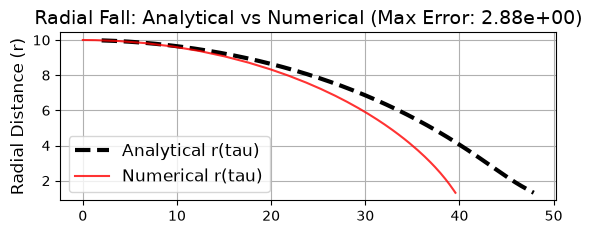

In [25]:
plt.subplot(2, 1, 1)
plt.plot(tau_vals, r_ana_vals, 'k--', linewidth=3, label='Analytical r(tau)')
plt.plot(tau_numerical, r_numerical, 'r-', linewidth=1.5, alpha=0.8, label='Numerical r(tau)')
plt.title(f"Radial Fall: Analytical vs Numerical (Max Error: {max_error:.2e})", fontsize=14)
plt.ylabel("Radial Distance (r)", fontsize=12)
plt.grid(True)
plt.legend(fontsize=12)

## Plot 2: The Conservation Cross-Check

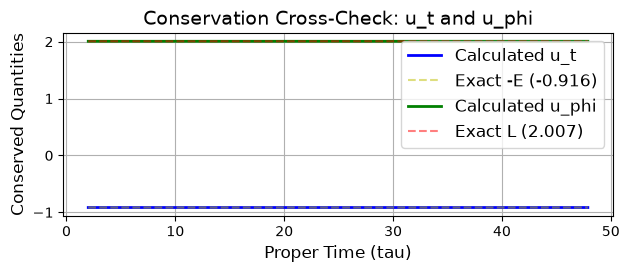

In [26]:
plt.subplot(2, 1, 2)
plt.plot(tau_vals, ut_vals, 'b-', linewidth=2, label='Calculated u_t')
plt.plot(tau_vals, [-E]*len(tau_vals), 'y--', alpha=0.5, label=f'Exact -E ({-E:.3f})')
plt.plot(tau_vals, uphi_vals, 'g-', linewidth=2, label='Calculated u_phi')
plt.plot(tau_vals, [L]*len(tau_vals), 'r--', alpha=0.5, label=f'Exact L ({L:.3f})')
plt.title("Conservation Cross-Check: u_t and u_phi", fontsize=14)
plt.xlabel("Proper Time (tau)", fontsize=12)
plt.ylabel("Conserved Quantities", fontsize=12)
plt.grid(True)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [27]:
# D2R = 6*r*(E**2-1)+4
r = [0,1,2,3,4,5,6,7,8,9,10]
for i in range(len(r)):
    print(f"D2R (r = {r[i]}) = {6*r[i]*(E**2-1)+4}")

print(f"D2R (r = {4.144083907}) = {6*4.144083907*(E**2-1)+4:0.3e}")

D2R (r = 0) = 4.0
D2R (r = 1) = 3.034940860000001
D2R (r = 2) = 2.0698817200000024
D2R (r = 3) = 1.1048225800000036
D2R (r = 4) = 0.13976344000000473
D2R (r = 5) = -0.8252956999999945
D2R (r = 6) = -1.790354839999993
D2R (r = 7) = -2.7554139799999913
D2R (r = 8) = -3.7204731199999905
D2R (r = 9) = -4.68553225999999
D2R (r = 10) = -5.650591399999989
D2R (r = 4.144083907) = 7.139e-04


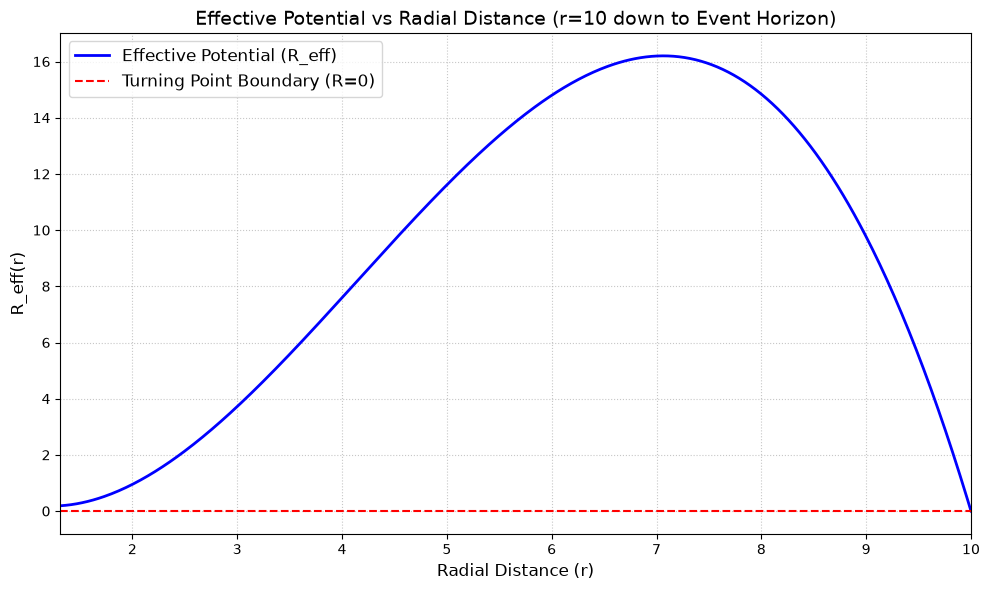

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the event horizon (r_plus) 
# The outer event horizon for Kerr is r+ = M + sqrt(M^2 - a^2)
r_plus = M + np.sqrt(M**2 - a**2)

# 2. Create an array of radial distances from the horizon up to the starting point
# Using 500 points for a smooth curve
r_vals = np.linspace(r_plus, 10.0, 500)

# 3. Calculate R_eff across all radial distances using the potential function
R_vals = R_eff(r_vals)

# 4. Plot of Effective Potential
plt.figure(figsize=(10, 6))
plt.plot(r_vals, R_vals, 'b-', linewidth=2, label='Effective Potential (R_eff)')

# Horizontal line at 0 to clearly show the turning point boundary
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Turning Point Boundary (R=0)')

# Formatting
plt.title("Effective Potential vs Radial Distance (r=10 down to Event Horizon)", fontsize=14)
plt.xlabel("Radial Distance (r)", fontsize=12)
plt.ylabel("R_eff(r)", fontsize=12)
plt.xlim(r_plus, 10.0)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()